# Notebook 1 — Exploring the SWELL-KW computer-interaction data

**Goal:** load the per-minute computer-interaction features of SWELL-KW, clean them, join the
participants' self-ratings (questionnaires), look at how the features differ between the three
working conditions, and save a clean file for Notebook 2.

**Inputs** (placed by hand in `ml/data/raw/`):

| File | What we use from it |
|---|---|
| `3 - Feature dataset/per sensor/A - Computer interaction features (Ulog - All Features per minute).xlsx` | sheet `Sheet1`: one row per participant-minute, columns A–T |
| `Behavioral-features - per minute.xlsx` | sheet `SWELLdata`: **only** the questionnaire columns (one rating per participant per condition) |

We do **not** use the facial-expression, posture or physiology columns (project rule: computer-interaction only).

**Output:** `ml/data/processed/swell_clean.csv`, plus charts and tables in `ml/reports/`.

Conditions: **N** = neutral, **I** = e-mail interruptions, **T** = time pressure, **R** = relax (watching a short film before each block; no computer use).

In [1]:
# --- Find the project folder so the notebook works from any working directory ---
import sys
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    """Walk up from `start` until we find the folder that contains shared/features.py."""
    for folder in [start, *start.parents]:
        if (folder / "shared" / "features.py").exists():
            return folder
    raise FileNotFoundError("Could not find the Commit project folder (shared/features.py).")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
sys.path.insert(0, str(REPO_ROOT))  # lets us "import shared.features"

RAW_DIR = REPO_ROOT / "ml" / "data" / "raw"
PROCESSED_DIR = REPO_ROOT / "ml" / "data" / "processed"
REPORTS_DIR = REPO_ROOT / "ml" / "reports"
MODELS_DIR = REPO_ROOT / "shared" / "models"
for folder in (PROCESSED_DIR, REPORTS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Project folder:", REPO_ROOT)

Project folder: /Users/matrix/Desktop/Commit


In [2]:
# --- Libraries ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [3]:
# --- Settings for this notebook (no magic numbers further down) ---

# Computer-interaction file and the sheet that holds the per-minute rows.
# (Sheet2 is the session schedule; Sheet3 is an older copy of Sheet1 with a broken
#  mouse-distance column — see ml/README.md.)
COMPUTER_FILE = RAW_DIR / "3 - Feature dataset" / "per sensor" / "A - Computer interaction features (Ulog - All Features per minute).xlsx"
COMPUTER_SHEET = "Sheet1"
COMPUTER_COLUMNS = "A:T"  # columns after T only hold two free-text notes ("uLog crashed...")

# Questionnaire data lives in the big behavioural file; we read only these columns from it.
BEHAVIOURAL_FILE = RAW_DIR / "Behavioral-features - per minute.xlsx"
BEHAVIOURAL_SHEET = "SWELLdata"
QUESTIONNAIRE_COLUMNS = [
    "MentalEffort",                      # RSME mental effort (used for the load label)
    "Stress",                            # perceived stress
    "NasaTLX",                           # NASA task-load index (combined)
    "MentalDemand", "PhysicalDemand", "TemporalDemand",
    "Effort", "Performance_rc", "Frustration",   # NASA-TLX sub-scales
    "Valence_rc", "Arousal_rc", "Dominance",     # SAM emotion scales (rc = recoded)
]

# Columns that identify a row.
KEY_COLUMNS = ["PP", "Blok", "Condition", "timestamp"]

# uLog wrote 999 in every column for minutes when it had crashed. These are not real counts.
CRASH_SENTINEL_VALUE = 999

# The three working conditions (R = relax is excluded from the analyses).
WORK_CONDITIONS = ["N", "I", "T"]
CONDITION_NAMES = {"N": "Neutral", "I": "Interruptions", "T": "Time pressure", "R": "Relax"}

# Significance level for the statistical tests (before Bonferroni correction).
SIGNIFICANCE_LEVEL = 0.05

## 1. Load the computer-interaction sheet and print the real column names

In [4]:
computer_raw = pd.read_excel(COMPUTER_FILE, sheet_name=COMPUTER_SHEET, usecols=COMPUTER_COLUMNS)

print("Shape (rows, columns):", computer_raw.shape)
print("\nColumn names:")
for name in computer_raw.columns:
    print("  ", name)

# The feature columns are everything after the four key columns.
FEATURE_COLUMNS = [name for name in computer_raw.columns if name not in KEY_COLUMNS]
print("\nNumber of feature columns:", len(FEATURE_COLUMNS))
computer_raw.head()

Shape (rows, columns): (3139, 20)

Column names:
   PP
   Blok
   Condition
   timestamp
   SnMouseAct
   SnLeftClicked
   SnRightClicked
   SnDoubleClicked
   SnWheel
   SnDragged
   SnMouseDistance
   SnKeyStrokes
   SnChars
   SnSpecialKeys
   SnDirectionKeys
   SnErrorKeys
   SnShortcutKeys
   SnSpaces
   SnAppChange
   SnTabfocusChange

Number of feature columns: 16


,PP,Blok,Condition,timestamp,SnMouseAct,SnLeftClicked,SnRightClicked,SnDoubleClicked,SnWheel,SnDragged,SnMouseDistance,SnKeyStrokes,SnChars,SnSpecialKeys,SnDirectionKeys,SnErrorKeys,SnShortcutKeys,SnSpaces,SnAppChange,SnTabfocusChange
0,PP1,1,R,20120918T131600000,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0
1,PP1,1,R,20120918T131700000,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0
2,PP1,1,R,20120918T131800000,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0
3,PP1,1,R,20120918T131900000,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0
4,PP1,1,R,20120918T132000000,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0


## 2. Clean the rows

Two known problems (found when we first inspected the files):

1. **Logger crashes:** 31 minutes (PP11 block 3 and PP16 block 2, both in the Interruptions condition) contain `999` in every column.
2. **Excel errors:** 2 cells of `SnMouseDistance` contain the text `#VALUE!`.

Both are removed, as agreed. We also turn the timestamp text (e.g. `20120918T131600000`) into a real date-time.

In [5]:
def clean_computer_rows(raw: pd.DataFrame) -> pd.DataFrame:
    """
    Clean the raw computer-interaction rows.

    In:  the raw Sheet1 table.
    Out: a copy with numeric feature columns, a parsed timestamp, and without
         crash rows (999) or rows with non-numeric values (#VALUE!).
    Why: those rows are not real measurements and would distort every statistic.
    """
    table = raw.copy()

    # Turn every feature into a number; text such as "#VALUE!" becomes NaN (missing).
    for name in FEATURE_COLUMNS:
        table[name] = pd.to_numeric(table[name], errors="coerce")

    # Find the problem rows.
    is_crash_row = (table[FEATURE_COLUMNS] == CRASH_SENTINEL_VALUE).all(axis=1)
    has_missing_value = table[FEATURE_COLUMNS].isna().any(axis=1)
    print("Crash rows (all 999):        ", int(is_crash_row.sum()))
    print("Rows with non-numeric values:", int(has_missing_value.sum()))

    # Keep only good rows.
    table = table[~is_crash_row & ~has_missing_value].copy()

    # Parse the timestamp: yyyymmddThhmmss + milliseconds.
    table["timestamp"] = pd.to_datetime(table["timestamp"], format="%Y%m%dT%H%M%S%f")
    table["Blok"] = table["Blok"].astype(int)
    return table.reset_index(drop=True)


computer = clean_computer_rows(computer_raw)
print("\nRows before:", len(computer_raw), " after:", len(computer))

Crash rows (all 999):         31
Rows with non-numeric values: 2

Rows before: 3139  after: 3106


## 3. Load the questionnaire ratings and join them

The participants filled in the questionnaires **once per condition**, so the behavioural file repeats
the same rating on every minute of a block. We reduce it to one row per (participant, block, condition)
and join it to the computer rows on those three columns. Relax blocks have no ratings.

In [6]:
behavioural = pd.read_excel(
    BEHAVIOURAL_FILE,
    sheet_name=BEHAVIOURAL_SHEET,
    usecols=["PP", "Blok", "Condition"] + QUESTIONNAIRE_COLUMNS,
)

# One row per block. Check that the rating really is constant inside each block.
block_keys = ["PP", "Blok", "Condition"]
ratings_per_block = behavioural.drop_duplicates()
assert not ratings_per_block.duplicated(block_keys).any(), "A block has more than one set of ratings"
ratings_per_block = ratings_per_block[ratings_per_block["Condition"].isin(WORK_CONDITIONS)].reset_index(drop=True)

print("Blocks with ratings:", len(ratings_per_block), "(25 participants x 3 conditions = 75 expected)")
print("\nMissing ratings per column (blocks):")
print(ratings_per_block[QUESTIONNAIRE_COLUMNS].isna().sum().to_string())
ratings_per_block.head()

Blocks with ratings: 75 (25 participants x 3 conditions = 75 expected)

Missing ratings per column (blocks):
MentalEffort      0
Stress            0
NasaTLX           3
MentalDemand      0
PhysicalDemand    0
TemporalDemand    0
Effort            0
Performance_rc    0
Frustration       0
Valence_rc        0
Arousal_rc        0
Dominance         0


,PP,Blok,Condition,Valence_rc,Arousal_rc,Dominance,Stress,MentalEffort,MentalDemand,PhysicalDemand,TemporalDemand,Effort,Performance_rc,Frustration,NasaTLX
0,PP1,1,N,6.0,4.0,6.0,4.1,5.1,0.7,0.7,5.0,5.0,4.9,5.2,50.7
1,PP1,2,T,6.0,5.0,7.0,5.9,7.7,2.3,4.7,6.7,6.2,3.8,4.7,61.0
2,PP1,3,I,5.0,7.0,4.0,3.5,8.4,3.8,5.1,5.7,6.4,3.2,5.1,60.7
3,PP2,1,N,5.0,3.0,2.0,1.4,1.3,2.4,4.5,6.5,3.5,5.0,1.0,39.4
4,PP2,2,I,9.0,1.0,9.0,3.4,3.8,4.0,1.4,4.3,3.4,9.5,0.6,26.1


In [7]:
# Join: every minute gets the ratings of its block. Relax minutes get empty (NaN) ratings.
swell = computer.merge(ratings_per_block, on=block_keys, how="left", validate="many_to_one")

rated_rows = swell[swell["Condition"].isin(WORK_CONDITIONS)]
print("N/I/T minutes without a MentalEffort rating:", int(rated_rows["MentalEffort"].isna().sum()))
print("Shape after join:", swell.shape)

N/I/T minutes without a MentalEffort rating: 0
Shape after join: (3106, 32)


## 4. Overview: rows, participants, conditions

In [8]:
print("Total rows (minutes):", len(swell))
print("Participants:", swell["PP"].nunique())
print("\nRows per condition:")
print(swell["Condition"].value_counts().rename(index=CONDITION_NAMES).to_string())

# Rows per participant and condition, participants in numeric order (PP1, PP2, ... PP25).
participant_order = sorted(swell["PP"].unique(), key=lambda name: int(name[2:]))
rows_per_participant = (
    swell.pivot_table(index="PP", columns="Condition", values="timestamp", aggfunc="count", fill_value=0)
    .reindex(participant_order)[["N", "I", "T", "R"]]
)
rows_per_participant["total"] = rows_per_participant.sum(axis=1)
rows_per_participant.to_csv(REPORTS_DIR / "eda_rows_per_participant.csv")
rows_per_participant

Total rows (minutes): 3106
Participants: 25

Rows per condition:
Condition
Neutral          1027
Interruptions     964
Time pressure     664
Relax             451


Condition,N,I,T,R,total
PP,,,,,
PP1,42,42,27,18,129
PP2,44,35,24,18,121
PP3,39,43,27,18,127
PP4,41,42,27,18,128
PP5,40,40,27,18,125
PP6,42,40,26,18,126
PP7,42,43,27,18,130
PP8,39,35,24,18,116
PP9,38,39,27,18,122


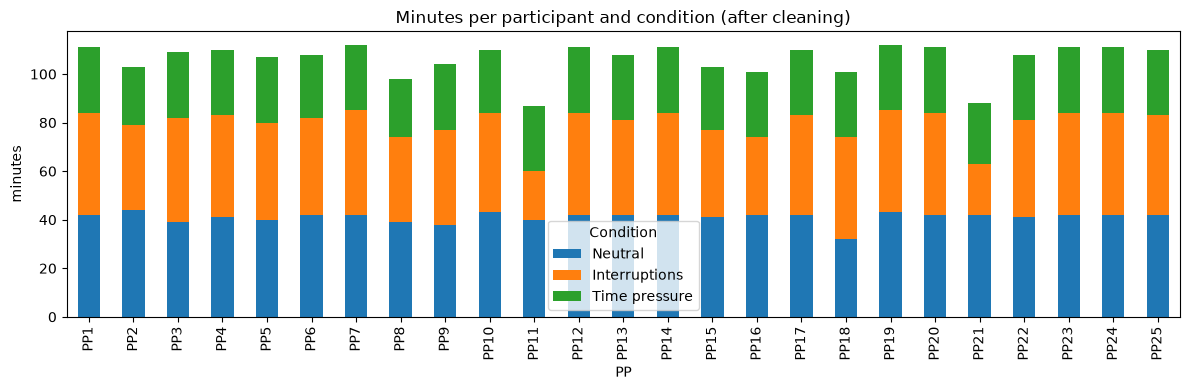

In [9]:
# Bar chart of N/I/T minutes per participant.
figure, axis = plt.subplots(figsize=(12, 4))
rows_per_participant[WORK_CONDITIONS].rename(columns=CONDITION_NAMES).plot(kind="bar", stacked=True, ax=axis)
axis.set_ylabel("minutes")
axis.set_title("Minutes per participant and condition (after cleaning)")
figure.tight_layout()
figure.savefig(REPORTS_DIR / "eda_rows_per_participant.png", dpi=150)
plt.show()

## 5. Missing values and duplicates

In [10]:
print("Missing values per column (feature columns):")
print(swell[FEATURE_COLUMNS].isna().sum().to_string())

duplicate_minutes = swell.duplicated(["PP", "timestamp"]).sum()
print("\nDuplicate (participant, minute) rows:", int(duplicate_minutes))

# Minutes with no computer input at all (all features 0), per condition.
all_zero = (swell[FEATURE_COLUMNS] == 0).all(axis=1)
print("\nMinutes with all features = 0, per condition:")
print(swell.loc[all_zero, "Condition"].value_counts().to_string())

# Is a minute missing inside a block? (time gap larger than 1 minute)
gaps = (
    swell.sort_values("timestamp")
    .groupby(["PP", "Blok", "Condition"])["timestamp"]
    .diff()
    .dt.total_seconds()
    .div(60)
)
print("\nGaps inside a block longer than 1 minute:", int((gaps > 1).sum()),
      "(these come from removing the crash rows)")

Missing values per column (feature columns):
SnMouseAct          0
SnLeftClicked       0
SnRightClicked      0
SnDoubleClicked     0
SnWheel             0
SnDragged           0
SnMouseDistance     0
SnKeyStrokes        0
SnChars             0
SnSpecialKeys       0
SnDirectionKeys     0
SnErrorKeys         0
SnShortcutKeys      0
SnSpaces            0
SnAppChange         0
SnTabfocusChange    0

Duplicate (participant, minute) rows: 0

Minutes with all features = 0, per condition:
Condition
R    405
N     12
I      8
T      2

Gaps inside a block longer than 1 minute: 2 (these come from removing the crash rows)


**Notes**

* Relax (R) minutes are almost all zero: participants watched a film. They are kept in the clean file but not used by the models.
* `SnKeyStrokes` always equals `SnChars + SnSpecialKeys` (checked during the first inspection), so those three columns overlap.

## 6. Features by condition (box plots)

Outliers are hidden to keep the boxes readable (`showfliers=False`).

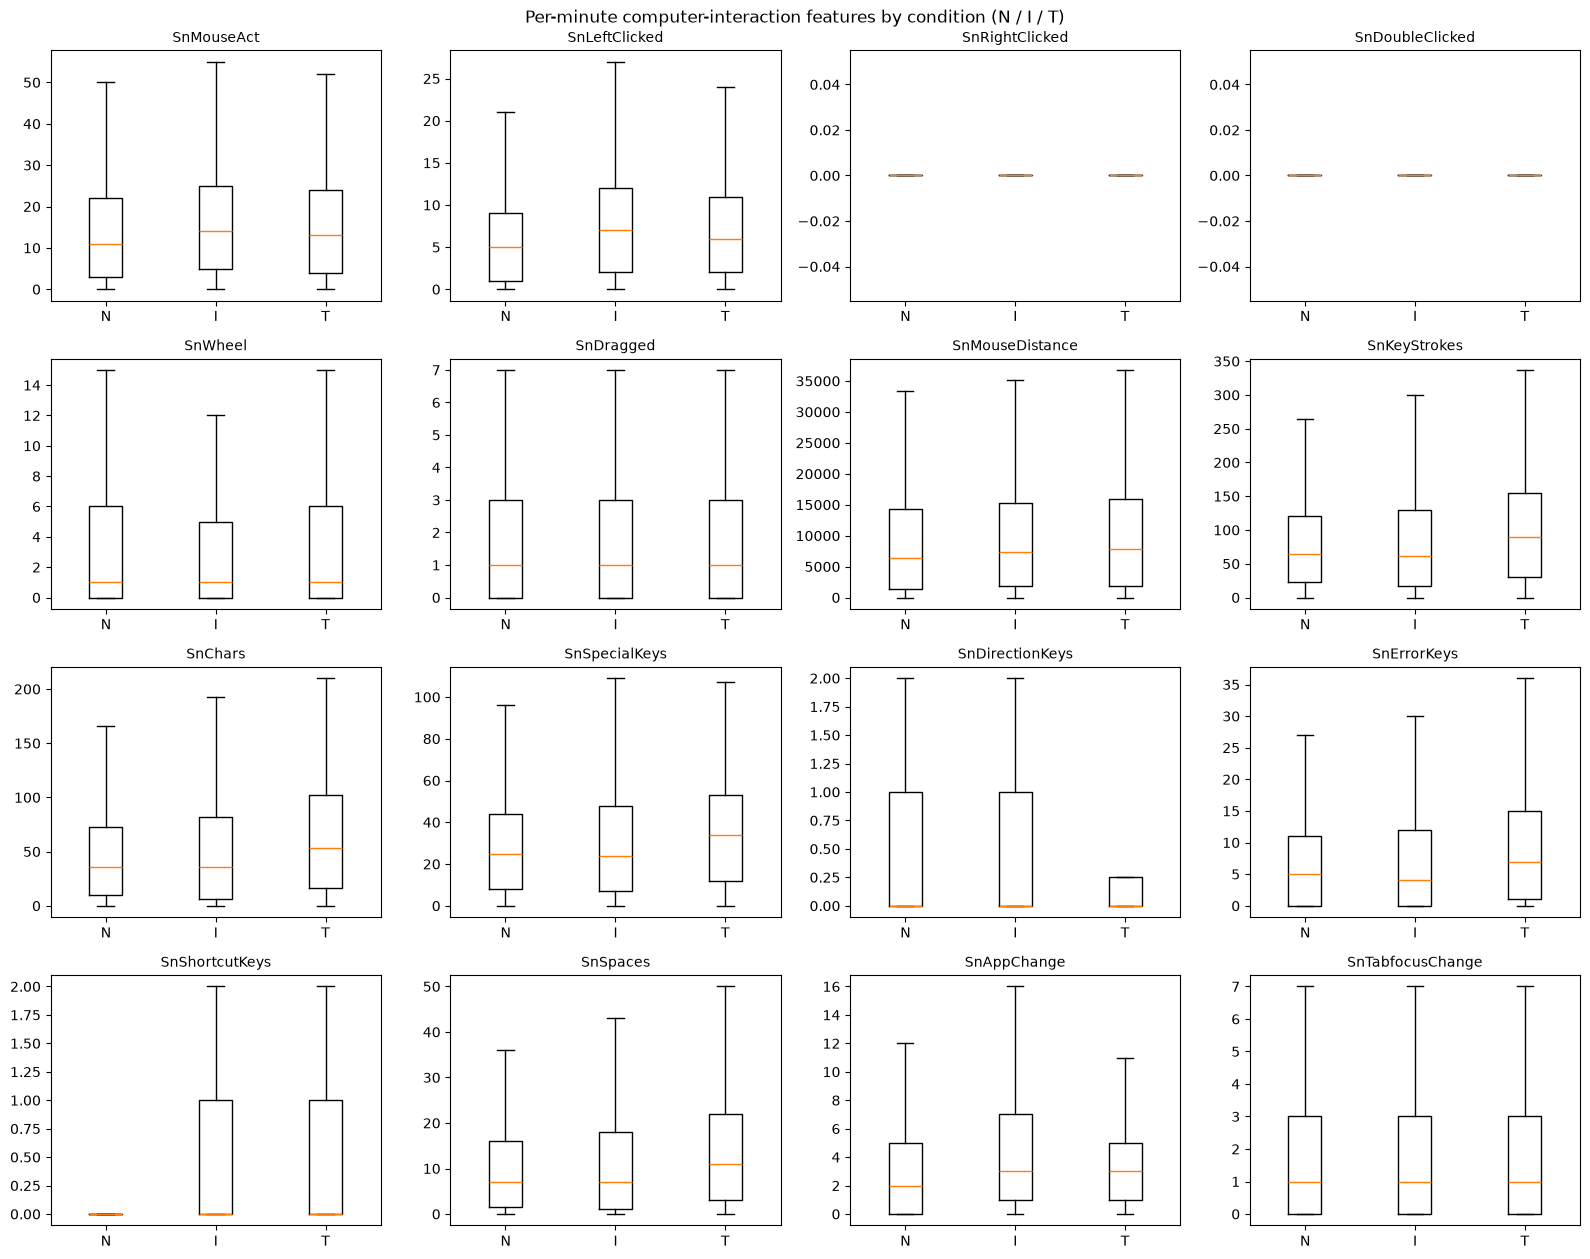

In [11]:
work = swell[swell["Condition"].isin(WORK_CONDITIONS)]

columns_per_row = 4
rows_of_plots = int(np.ceil(len(FEATURE_COLUMNS) / columns_per_row))
figure, axes = plt.subplots(rows_of_plots, columns_per_row, figsize=(16, 3.2 * rows_of_plots))

for axis, feature in zip(axes.flat, FEATURE_COLUMNS):
    values_per_condition = [work.loc[work["Condition"] == condition, feature] for condition in WORK_CONDITIONS]
    axis.boxplot(values_per_condition, showfliers=False)
    axis.set_xticks(range(1, len(WORK_CONDITIONS) + 1), labels=WORK_CONDITIONS)
    axis.set_title(feature, fontsize=10)

# Hide unused panels, if any.
for axis in axes.flat[len(FEATURE_COLUMNS):]:
    axis.set_visible(False)

figure.suptitle("Per-minute computer-interaction features by condition (N / I / T)")
figure.tight_layout()
figure.savefig(REPORTS_DIR / "eda_boxplots_by_condition.png", dpi=150)
plt.show()

## 7. Do the features differ between N, I and T?

Two tests per feature:

* **Kruskal-Wallis** on all minutes (as the project plan asks). Caution: minutes from the same person are not independent, so its p-values are too optimistic.
* **Friedman** on each participant's *mean* per condition (25 people x 3 conditions). This respects that every person did all three conditions, so it is the fairer test.

We test 16 features, so we also show a **Bonferroni** correction (p x 16).

In [12]:
def test_feature_across_conditions(table: pd.DataFrame, feature: str) -> dict:
    """
    Run Kruskal-Wallis (per minute) and Friedman (per participant mean) for one feature.

    In:  N/I/T rows and the feature name.
    Out: a dict with the medians per condition and both tests' statistics and p-values.
    Why: shows which features change with the working condition.
    """
    minute_groups = [table.loc[table["Condition"] == c, feature] for c in WORK_CONDITIONS]
    kruskal = stats.kruskal(*minute_groups)

    # Per-participant mean per condition -> 25 x 3 table.
    person_means = table.pivot_table(index="PP", columns="Condition", values=feature, aggfunc="mean")[WORK_CONDITIONS]
    friedman = stats.friedmanchisquare(*[person_means[c] for c in WORK_CONDITIONS])

    result = {"feature": feature}
    for condition, values in zip(WORK_CONDITIONS, minute_groups):
        result[f"median_{condition}"] = values.median()
    result.update({
        "kruskal_H": kruskal.statistic, "kruskal_p": kruskal.pvalue,
        "friedman_chi2": friedman.statistic, "friedman_p": friedman.pvalue,
    })
    return result


feature_tests = pd.DataFrame([test_feature_across_conditions(work, f) for f in FEATURE_COLUMNS])
number_of_tests = len(FEATURE_COLUMNS)
feature_tests["kruskal_p_bonferroni"] = (feature_tests["kruskal_p"] * number_of_tests).clip(upper=1)
feature_tests["friedman_p_bonferroni"] = (feature_tests["friedman_p"] * number_of_tests).clip(upper=1)
feature_tests["friedman_significant"] = feature_tests["friedman_p_bonferroni"] < SIGNIFICANCE_LEVEL
feature_tests = feature_tests.sort_values("friedman_p")
feature_tests.to_csv(REPORTS_DIR / "eda_feature_tests.csv", index=False)
feature_tests.round(4)

,feature,median_N,median_I,median_T,kruskal_H,kruskal_p,friedman_chi2,friedman_p,kruskal_p_bonferroni,friedman_p_bonferroni,friedman_significant
14,SnAppChange,2.0000,3.0000,3.0000,60.5907,0.0000,14.4800,0.0007,0.0000,0.0115,True
2,SnRightClicked,0.0000,0.0000,0.0000,20.4769,0.0000,12.1237,0.0023,0.0006,0.0373,True
8,SnChars,36.0000,36.0000,53.0000,39.9507,0.0000,12.0800,0.0024,0.0000,0.0381,True
10,SnDirectionKeys,0.0000,0.0000,0.0000,4.5928,0.1006,8.8800,0.0118,1.0000,0.1887,False
7,SnKeyStrokes,64.0000,62.0000,89.0000,34.5307,0.0000,7.4400,0.0242,0.0000,0.3877,False
13,SnSpaces,7.0000,7.0000,11.0000,30.9392,0.0000,7.4400,0.0242,0.0000,0.3877,False
12,SnShortcutKeys,0.0000,0.0000,0.0000,28.9850,0.0000,6.9293,0.0313,0.0000,0.5005,False
1,SnLeftClicked,5.0000,7.0000,6.0000,33.3383,0.0000,6.7200,0.0347,0.0000,0.5558,False
9,SnSpecialKeys,25.0000,24.0000,34.0000,21.3844,0.0000,6.4800,0.0392,0.0004,0.6266,False
3,SnDoubleClicked,0.0000,0.0000,0.0000,6.4574,0.0396,4.0202,0.1340,0.6337,1.0000,False


## 8. Self-ratings: does mental effort follow the condition?

The load label (Notebook 2) comes from the **MentalEffort** (RSME) rating. If the ratings simply copied the
condition, a separate load model would add nothing. Here we check how much they agree.

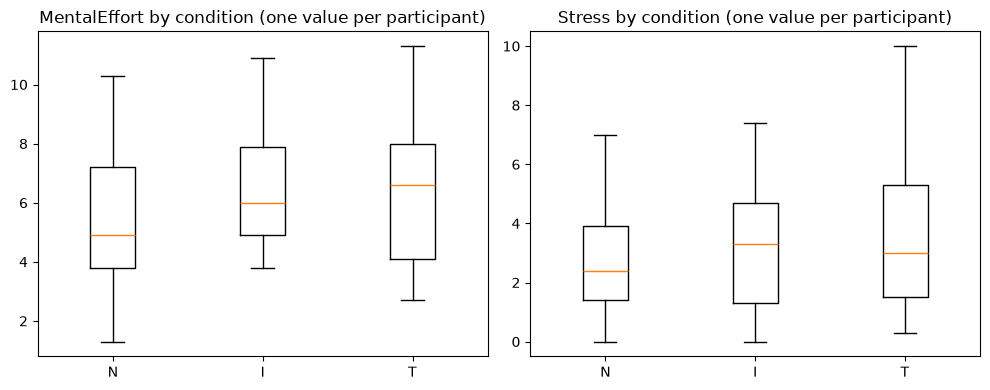

Mean MentalEffort per condition:
Condition
N    5.54
I    6.53
T    6.32

Friedman test on MentalEffort: chi2 = 7.17, p = 0.0277
Participants whose neutral block got the strictly lowest effort rating: 13 of 25


In [13]:
ratings = ratings_per_block.copy()

# Box plots of mental effort and stress per condition.
figure, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["MentalEffort", "Stress"]):
    axis.boxplot([ratings.loc[ratings["Condition"] == c, column].dropna() for c in WORK_CONDITIONS])
    axis.set_xticks(range(1, len(WORK_CONDITIONS) + 1), labels=WORK_CONDITIONS)
    axis.set_title(f"{column} by condition (one value per participant)")
figure.tight_layout()
figure.savefig(REPORTS_DIR / "eda_questionnaire_by_condition.png", dpi=150)
plt.show()

# Friedman test: does MentalEffort differ between conditions within people?
effort = ratings.pivot_table(index="PP", columns="Condition", values="MentalEffort")[WORK_CONDITIONS]
friedman_effort = stats.friedmanchisquare(*[effort[c] for c in WORK_CONDITIONS])
print("Mean MentalEffort per condition:")
print(effort.mean().round(2).to_string())
print(f"\nFriedman test on MentalEffort: chi2 = {friedman_effort.statistic:.2f}, p = {friedman_effort.pvalue:.4f}")

# For how many people is neutral their LOWEST-effort condition?
lowest_is_neutral = (effort["N"] < effort[["I", "T"]].min(axis=1)).sum()
print(f"Participants whose neutral block got the strictly lowest effort rating: {lowest_is_neutral} of {len(effort)}")

ratings.to_csv(REPORTS_DIR / "eda_questionnaire_per_block.csv", index=False)

## 9. Save the clean data

The clean file keeps **all** conditions (including R) and the SWELL column names. Notebook 2 renames the
columns to our own feature names and builds the model features.

In [14]:
output_file = PROCESSED_DIR / "swell_clean.csv"
swell.to_csv(output_file, index=False)
print("Saved", output_file, "with shape", swell.shape)

Saved /Users/matrix/Desktop/Commit/ml/data/processed/swell_clean.csv with shape (3106, 32)


## Summary

* After removing 31 crash minutes and 2 `#VALUE!` rows: **3,106 minutes** from **25 participants**.
* Self-ratings (one per participant per condition) were joined for all 75 N/I/T blocks; PP15 has no NASA-TLX score but does have MentalEffort and Stress.
* The feature tests table (`ml/reports/eda_feature_tests.csv`) shows which features change with the condition. The per-participant Friedman test is the one to trust.
* The mental-effort check shows how far the self-ratings agree with the experimental condition, which matters for the load label.